# Week 2: Feature Engineering & Baseline Forecasts

**Input:** `data/processed/weekly_product_demand.csv` (from the Week 1 notebook)

| Deliverable | Where |
|---|---|
| Feature-engineering scripts | `src/features.py`, `src/splits.py`, `src/baselines.py`, `src/evaluation.py` |
| Chronological split plan | `reports/split_plan.csv` + section 4 |
| Product scope (aggregation level) | `reports/product_selection.csv` |
| Model-ready feature tables | `data/processed/features_h1.csv`, `data/processed/features_h4.csv` |
| Feature dictionary | `reports/feature_dictionary.csv` |
| Baseline forecasts | `data/processed/baseline_forecasts.csv` |
| Initial evaluation table | `reports/baseline_evaluation.csv`, `reports/baseline_evaluation_total.csv` |
| Error by product | `reports/baseline_error_by_product.csv` |
| Figures | `reports/figures/2*_*.png` |

## 1. Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.data_cleaning import load_weekly_panel
from src.splits import (HORIZONS, TRAIN_START, TRAIN_END, VALID_START, VALID_END,
                        TEST_START, TEST_END, model_ready_panel, select_products, split_plan_table)
from src.features import make_features, feature_dictionary, feature_columns, check_no_leakage
from src.baselines import baseline_forecasts, BASELINE_COLUMNS
from src.evaluation import evaluation_table, error_by_product

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "reports"
FIG_DIR = REPORT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

panel = load_weekly_panel(PROCESSED_DIR / "weekly_product_demand.csv")
print("Weekly panel:", panel.shape, "| products:", panel["StockCode"].nunique())

Weekly panel: (176363, 10) | products: 3786


## 2. Handling missing dates and stockouts

| Situation | Handling |
|---|---|
| **Shop closed all week** (27 Dec 2010) | Removed. Lags skip over it, so lag 1 of the 3 Jan 2011 week is the 20 Dec 2010 week. |
| **Partial weeks** (first week 29 Nov 2010, last week 5 Dec 2011) | Removed, so a short week is never read as low demand. |
| **Short trading weeks** (Christmas, Easter, bank holidays) | Kept. `trading_days` and `n_bank_holidays` are model features; both are known in advance. |
| **Weeks before a product's first sale** | Not in the panel, so they are never filled with zeros. |
| **Open week with no sales** | True zero demand (`units_sold = 0`). |
| **Stockouts** | **Cannot be identified.** The data has no inventory or stockout fields, so a zero or low week may be a stockout. We do not impute demand; this is a stated limitation, and forecasts may understate unconstrained demand. |
| **Promotions** | No promotion field. `price_vs_8wk_mean` is a price-change proxy built from past prices only. |

## 3. Aggregation level and product scope

In [2]:
selection = select_products(panel)
selection.to_csv(REPORT_DIR / "product_selection.csv", index=False)

n_sel = selection["selected"].sum()
vol_share = selection.loc[selection["selected"], "train_units"].sum() / selection["train_units"].sum()
print(f"Products with sales in train period: {len(selection):,}")
print(f"Present for the whole train period:  {selection['full_train_history'].sum():,}")
print(f"Selected (also sold in ≥80% of train weeks): {n_sel:,}  → {vol_share:.1%} of train units")

selected_codes = selection.loc[selection["selected"], "StockCode"]
mp = model_ready_panel(panel)
mp = mp[mp["StockCode"].isin(selected_codes)].reset_index(drop=True)
print("Model panel:", mp.shape)

Products with sales in train period: 3,492
Present for the whole train period:  2,473
Selected (also sold in ≥80% of train weeks): 978  → 70.4% of train units
Model panel: (49878, 11)


**Decision:** forecast at **weekly × product (StockCode)** level for the selected products.
The data has no store dimension, so product-store level isn't possible.
The selection uses **train weeks only**, so no validation or test information affects the scope.
The other products (sparse, new or discontinued) are too intermittent for product-level models.
Week 3 can handle them with simple rules, such as a moving average or a category-level forecast.

## 4. Forecast horizons and chronological split

**Horizons**
- **h = 1:** next week's demand, for operational monitoring.
- **h = 4:** demand four weeks ahead, for replenishment planning (lead-time demand in Week 3).

Each horizon gets its own feature table (direct strategy). For a target week *t*, every demand feature uses weeks ≤ *t − h* only.

In [3]:
split_plan = split_plan_table(panel)
split_plan.to_csv(REPORT_DIR / "split_plan.csv", index=False)
display(split_plan)

,split,start_week,end_week,open_weeks,notes
0,train,2010-12-06,2011-08-08,35,Fit models and baselines. Includes Dec-2010 pe...
1,validation,2011-08-15,2011-10-03,8,Tune hyper-parameters and choose models. Start...
2,test,2011-10-10,2011-11-28,8,"Final evaluation only, never used for tuning. ..."
3,excluded,None,None,3,"Removed: 2010-11-29, 2010-12-27, 2011-12-05 (c..."


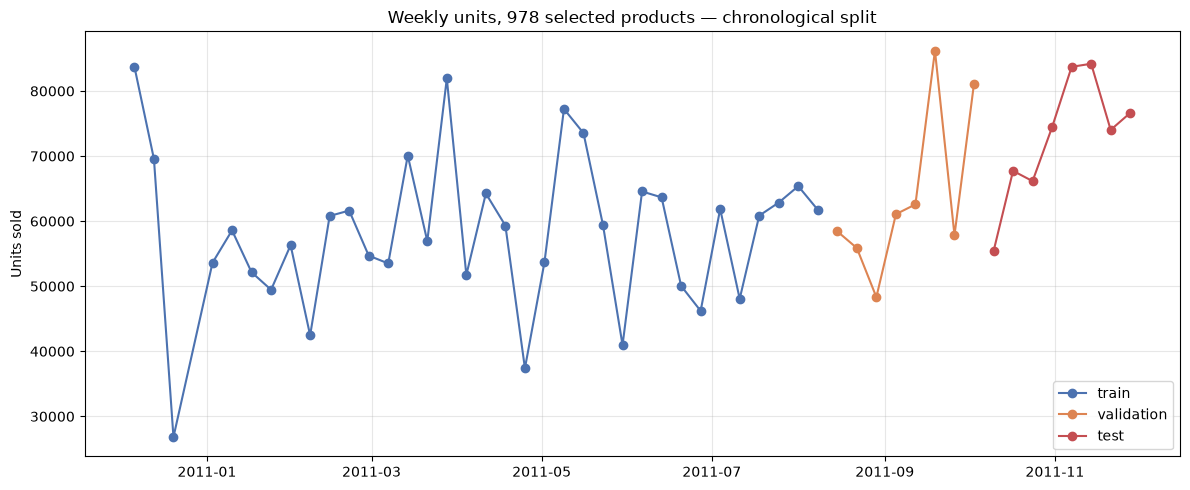

In [4]:
total = mp.groupby(["week_start", "split"])["units_sold"].sum().reset_index()
colors = {"train": "#4C72B0", "validation": "#DD8452", "test": "#C44E52"}
fig, ax = plt.subplots(figsize=(12, 5))
for s in ["train", "validation", "test"]:
    part = total[total["split"] == s]
    ax.plot(part["week_start"], part["units_sold"], marker="o", color=colors[s], label=s)
ax.set_title(f"Weekly units, {mp['StockCode'].nunique()} selected products — chronological split")
ax.set_ylabel("Units sold"); ax.grid(alpha=0.3); ax.legend()
save_fig("21_split_plan")

Validation and test fall in the autumn ramp-up and the pre-Christmas peak. The train period has no earlier autumn to learn this from,
so every method, the baselines included, is tested on a level shift it has not seen. This is a real limitation of a one-year dataset.

## 5. Feature engineering

In [5]:
features = {}
for h in HORIZONS:
    f = make_features(mp, horizon=h)
    f.to_csv(PROCESSED_DIR / f"features_h{h}.csv", index=False)
    features[h] = f
    print(f"h={h}: {f.shape[0]:,} rows × {len(feature_columns(h))} features | "
          f"rows with full lag history: {f['has_full_history'].mean():.1%}")

feat_dict = pd.concat([feature_dictionary(h) for h in HORIZONS], ignore_index=True)
feat_dict.to_csv(REPORT_DIR / "feature_dictionary.csv", index=False)
display(feature_dictionary(1))

h=1: 49,878 rows × 28 features | rows with full lag history: 76.5%
h=4: 49,878 rows × 28 features | rows with full lag history: 70.6%


,feature,description,uses data up to,horizon
0,lag_1,Units sold k open weeks before the target week,origin (t-1) or earlier,1
1,lag_2,Units sold k open weeks before the target week,origin (t-1) or earlier,1
2,lag_3,Units sold k open weeks before the target week,origin (t-1) or earlier,1
3,lag_4,Units sold k open weeks before the target week,origin (t-1) or earlier,1
4,lag_8,Units sold k open weeks before the target week,origin (t-1) or earlier,1
5,lag_12,Units sold k open weeks before the target week,origin (t-1) or earlier,1
6,roll_mean_4,Mean weekly units over the 4 weeks ending at t...,origin,1
7,roll_std_4,Std of weekly units over the 4 weeks ending at...,origin,1
8,roll_mean_8,Mean weekly units over the 8 weeks ending at t...,origin,1
9,roll_std_8,Std of weekly units over the 8 weeks ending at...,origin,1


In [6]:
display(features[1][features[1]["split"] == "test"].head())

,StockCode,Description,week_start,horizon,split,units_sold,trading_days,lag_1,lag_2,lag_3,lag_4,lag_8,lag_12,roll_mean_4,roll_std_4,roll_mean_8,roll_std_8,roll_mean_12,roll_std_12,roll_max_8,share_weeks_with_sales_8,ewm_mean,weeks_since_last_sale,trend_4_vs_12,orders_lag_h,orders_roll_mean_4,price_last_known,price_vs_8wk_mean,product_age_weeks,week_of_year,month,quarter,n_bank_holidays,weeks_to_christmas,origin_week,has_full_history
43,10133,COLOURING PENCILS BROWN TUBE,2011-10-10,1,test,0,6,0.00,0.00,0.00,0.00,245.00,219.00,0.00,0.00,87.25,113.08,111.58,100.87,245.00,0.50,34.72,4.00,0.00,0.00,0.00,0.42,0.91,43,41,10,4,0,10,2011-10-03,True
44,10133,COLOURING PENCILS BROWN TUBE,2011-10-17,1,test,0,6,0.00,0.00,0.00,0.00,215.00,160.00,0.00,0.00,56.62,96.17,93.33,99.47,215.00,0.38,24.31,5.00,0.00,0.00,0.00,0.42,0.91,44,42,10,4,0,9,2011-10-10,True
45,10133,COLOURING PENCILS BROWN TUBE,2011-10-24,1,test,0,6,0.00,0.00,0.00,0.00,208.00,170.00,0.00,0.00,29.75,72.78,80.00,100.44,208.00,0.25,17.01,6.00,0.00,0.00,0.00,0.42,0.91,45,43,10,4,0,8,2011-10-17,True
46,10133,COLOURING PENCILS BROWN TUBE,2011-10-31,1,test,0,6,0.00,0.00,0.00,0.00,30.00,92.00,0.00,0.00,3.75,10.61,65.83,98.57,30.00,0.12,11.91,7.00,0.00,0.00,0.00,0.42,1.00,46,44,10,4,0,7,2011-10-24,True
47,10133,COLOURING PENCILS BROWN TUBE,2011-11-07,1,test,0,6,0.00,0.00,0.00,0.00,0.00,245.00,0.00,0.00,0.00,0.00,58.17,99.92,0.00,0.00,8.34,8.00,0.00,0.00,0.00,0.42,1.00,47,45,11,4,0,6,2011-10-31,True


## 6. Leakage checks

1. **Scramble test:** every target value after a cutoff is randomly reshuffled and the features are rebuilt. Features for weeks
   up to the cutoff + h must not change. If any did, that feature would be reading future demand.
2. **Origin check:** for every row, the forecast origin is exactly *h* open weeks before the target week.
3. **Sanity check:** no feature should be almost perfectly correlated with the target. A correlation near 1 is a typical sign of leakage.

In [7]:
cutoffs = [TRAIN_END, VALID_END, pd.Timestamp("2011-05-02")]
results = []
for h in HORIZONS:
    for c in cutoffs:
        ok = check_no_leakage(mp, horizon=h, cutoff=c)
        results.append({"horizon": h, "cutoff": c.date(), "features_unchanged": ok})
leak = pd.DataFrame(results)
display(leak)
assert leak["features_unchanged"].all(), "Leakage detected!"

for h in HORIZONS:
    f = features[h].dropna(subset=["origin_week"])
    weeks = pd.Index(np.sort(mp["week_start"].unique()))
    gap = weeks.get_indexer(f["week_start"]) - weeks.get_indexer(f["origin_week"])
    assert (gap == h).all()
print("All leakage checks passed.")

,horizon,cutoff,features_unchanged
0,1,2011-08-08,True
1,1,2011-10-03,True
2,1,2011-05-02,True
3,4,2011-08-08,True
4,4,2011-10-03,True
5,4,2011-05-02,True


All leakage checks passed.


In [8]:
train1 = features[1][features[1]["split"] == "train"]
corr = (train1[feature_columns(1)].corrwith(train1["units_sold"])
        .sort_values(key=np.abs, ascending=False).to_frame("corr_with_target (train, h=1)"))
display(corr.head(10))
assert corr.abs().max().iloc[0] < 0.98

,"corr_with_target (train, h=1)"
roll_mean_12,0.63
roll_mean_8,0.62
roll_mean_4,0.58
ewm_mean,0.57
roll_max_8,0.51
roll_std_12,0.50
roll_std_8,0.47
lag_8,0.46
lag_1,0.46
lag_4,0.45


## 7. Baseline forecasts

| Baseline | Forecast for week *t* at horizon *h* |
|---|---|
| `naive` | demand in the origin week *t − h* |
| `moving_avg_4` | mean of the 4 weeks ending at the origin |
| `seasonal_naive_52` | demand in the same week last year (*t − 52*) |
| `seasonal_naive_4` | demand 4 weeks earlier, a "same week last month" proxy. For h = 4 it is identical to `naive`. |

The data covers only about 12 months (Dec 2010 – Dec 2011), so **`seasonal_naive_52` has no history for any evaluation week**.
It is still computed, and its 0% coverage is reported, so the limitation is shown rather than hidden.

In [9]:
baselines = pd.concat([baseline_forecasts(mp, h) for h in HORIZONS], ignore_index=True)
baselines.to_csv(PROCESSED_DIR / "baseline_forecasts.csv", index=False)
display(baselines[baselines["split"] == "test"].head())

,StockCode,week_start,horizon,split,units_sold,naive,moving_avg_4,seasonal_naive_4,seasonal_naive_52
43,10133,2011-10-10,1,test,0,0.00,0.00,0.00,NaN
44,10133,2011-10-17,1,test,0,0.00,0.00,0.00,NaN
45,10133,2011-10-24,1,test,0,0.00,0.00,0.00,NaN
46,10133,2011-10-31,1,test,0,0.00,0.00,0.00,NaN
47,10133,2011-11-07,1,test,0,0.00,0.00,0.00,NaN


## 8. Initial evaluation table

In [10]:
eval_rows = baselines[baselines["split"].isin(["validation", "test"])]
evaluation = evaluation_table(eval_rows, BASELINE_COLUMNS, by=["horizon", "split"])
evaluation.to_csv(REPORT_DIR / "baseline_evaluation.csv", index=False)
display(evaluation)

,horizon,split,method,coverage_%,n,MAE,RMSE,WAPE_%,Bias_%,MAPE_%_nonzero
0,1,test,naive,100.00,"7,824.00",54.65,154.19,73.43,0.77,184.66
1,1,test,moving_avg_4,100.00,"7,824.00",45.97,121.51,61.78,-2.05,177.94
2,1,test,seasonal_naive_4,100.00,"7,824.00",57.43,158.24,77.17,-5.29,219.88
3,1,test,seasonal_naive_52,0.00,NaN,NaN,NaN,NaN,NaN,NaN
4,1,validation,naive,100.00,"7,824.00",52.44,128.48,80.23,-3.79,212.06
5,1,validation,moving_avg_4,100.00,"7,824.00",44.42,107.10,67.95,-5.05,183.69
6,1,validation,seasonal_naive_4,100.00,"7,824.00",53.94,136.92,82.52,-7.22,215.45
7,1,validation,seasonal_naive_52,0.00,NaN,NaN,NaN,NaN,NaN,NaN
8,4,test,naive,100.00,"7,824.00",57.43,158.24,77.17,-5.29,219.88
9,4,test,moving_avg_4,100.00,"7,824.00",48.96,130.46,65.79,-9.05,180.76


**Product-week level:** each row is one product in one week, and all methods are scored on the same rows.
WAPE is the main comparison metric because many weeks have zero demand. MAPE is shown for reference only, on non-zero weeks.

In [11]:
# Total level: sum the product forecasts per week and compare with total demand
tot = (eval_rows.groupby(["horizon", "split", "week_start"])[["units_sold"] + BASELINE_COLUMNS]
       .sum(min_count=1).reset_index())
evaluation_total = evaluation_table(tot, BASELINE_COLUMNS, by=["horizon", "split"])
evaluation_total.to_csv(REPORT_DIR / "baseline_evaluation_total.csv", index=False)
display(evaluation_total)

,horizon,split,method,coverage_%,n,MAE,RMSE,WAPE_%,Bias_%,MAPE_%_nonzero
0,1,test,naive,100.00,8.00,"8,816.88","11,645.90",12.11,0.77,13.39
1,1,test,moving_avg_4,100.00,8.00,"7,624.66","9,906.23",10.48,-2.05,10.70
2,1,test,seasonal_naive_4,100.00,8.00,"11,947.00","14,356.29",16.41,-5.29,16.10
3,1,test,seasonal_naive_52,0.00,NaN,NaN,NaN,NaN,NaN,NaN
4,1,validation,naive,100.00,8.00,"12,870.88","16,374.28",20.13,-3.79,19.29
5,1,validation,moving_avg_4,100.00,8.00,"10,543.47","13,102.03",16.49,-5.05,15.65
6,1,validation,seasonal_naive_4,100.00,8.00,"11,401.62","14,903.42",17.83,-7.22,17.01
7,1,validation,seasonal_naive_52,0.00,NaN,NaN,NaN,NaN,NaN,NaN
8,4,test,naive,100.00,8.00,"11,947.00","14,356.29",16.41,-5.29,16.10
9,4,test,moving_avg_4,100.00,8.00,"7,180.62","9,411.73",9.87,-9.05,9.15


In [12]:
best = (evaluation.dropna(subset=["WAPE_%"])
        .sort_values("WAPE_%").groupby(["horizon", "split"]).head(1))
display(best[["horizon", "split", "method", "MAE", "RMSE", "WAPE_%", "Bias_%"]])

,horizon,split,method,MAE,RMSE,WAPE_%,Bias_%
1,1,test,moving_avg_4,45.97,121.51,61.78,-2.05
9,4,test,moving_avg_4,48.96,130.46,65.79,-9.05
5,1,validation,moving_avg_4,44.42,107.10,67.95,-5.05
13,4,validation,moving_avg_4,45.38,106.33,69.42,-8.28


### Error by product

Products with the largest absolute error (moving_avg_4, h=1, validation):


,StockCode,Description,MAE,WAPE_%,Bias_%
0,85099B,JUMBO BAG RED RETROSPOT,593.69,47.72,-17.37
1,84568,GIRLS ALPHABET IRON ON PATCHES,577.84,281.53,106.35
2,21915,RED HARMONICA IN BOX,514.78,74.12,-20.06
3,84879,ASSORTED COLOUR BIRD ORNAMENT,514.44,81.22,55.06
4,22969,HOMEMADE JAM SCENTED CANDLES,417.00,103.09,-32.96
5,22197,POPCORN HOLDER,394.38,47.96,17.74
6,21787,RAIN PONCHO RETROSPOT,391.06,110.55,-28.18
7,84212,"ASSORTED FLOWER COLOUR ""LEIS""",388.31,120.41,2.38
8,20971,PINK BLUE FELT CRAFT TRINKET BOX,373.94,97.73,-49.98
9,21212,PACK OF 72 RETROSPOT CAKE CASES,372.81,48.53,-3.34


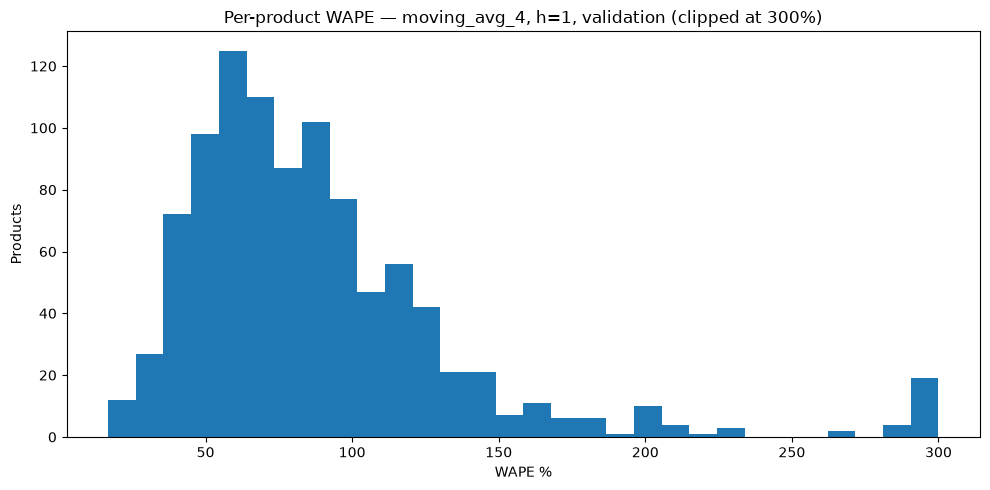

In [13]:
val1 = baselines[(baselines["horizon"] == 1) & (baselines["split"] == "validation")]
by_prod = error_by_product(val1, "moving_avg_4")
by_prod = by_prod.merge(mp[["StockCode", "Description"]].drop_duplicates("StockCode"), on="StockCode")
by_prod.to_csv(REPORT_DIR / "baseline_error_by_product.csv", index=False)

print("Products with the largest absolute error (moving_avg_4, h=1, validation):")
display(by_prod.head(10)[["StockCode", "Description", "MAE", "WAPE_%", "Bias_%"]])

by_prod["WAPE_%"].clip(upper=300).plot(kind="hist", bins=30, figsize=(10, 5),
    title="Per-product WAPE — moving_avg_4, h=1, validation (clipped at 300%)")
plt.xlabel("WAPE %"); plt.ylabel("Products")
save_fig("22_wape_by_product_hist")

### Actual vs baseline forecasts

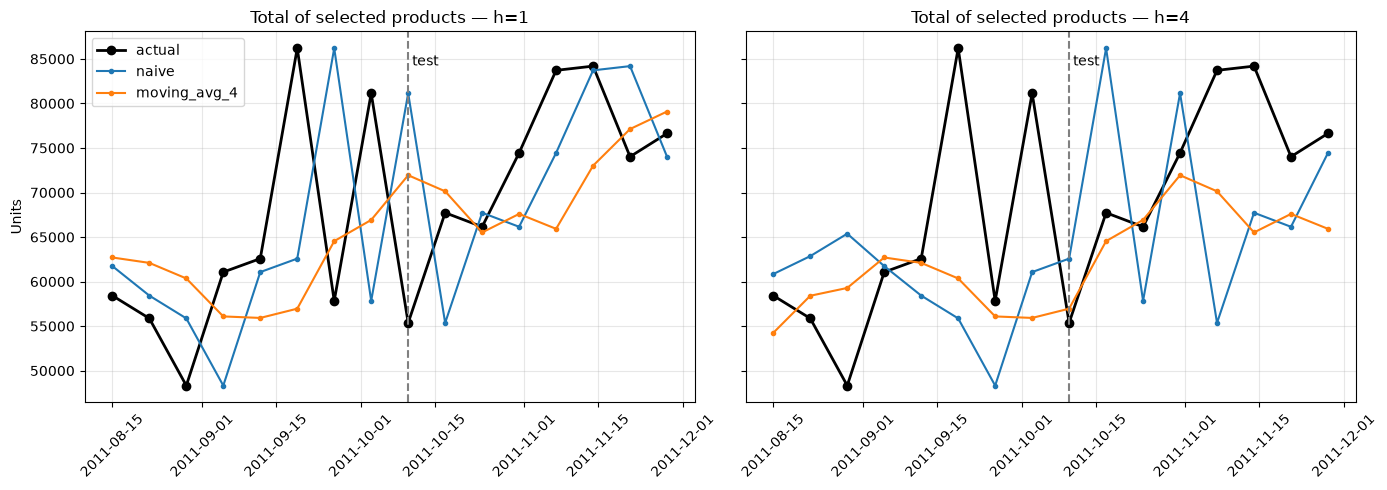

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, h in zip(axes, HORIZONS):
    t = tot[tot["horizon"] == h].sort_values("week_start")
    ax.plot(t["week_start"], t["units_sold"], "k-o", label="actual", linewidth=2)
    for m in ["naive", "moving_avg_4"]:
        ax.plot(t["week_start"], t[m], marker=".", label=m)
    ax.axvline(TEST_START, color="grey", linestyle="--")
    ax.text(TEST_START, ax.get_ylim()[1] * 0.97, " test", va="top")
    ax.set_title(f"Total of selected products — h={h}")
    ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Units"); axes[0].legend()
save_fig("23_total_actual_vs_baselines")

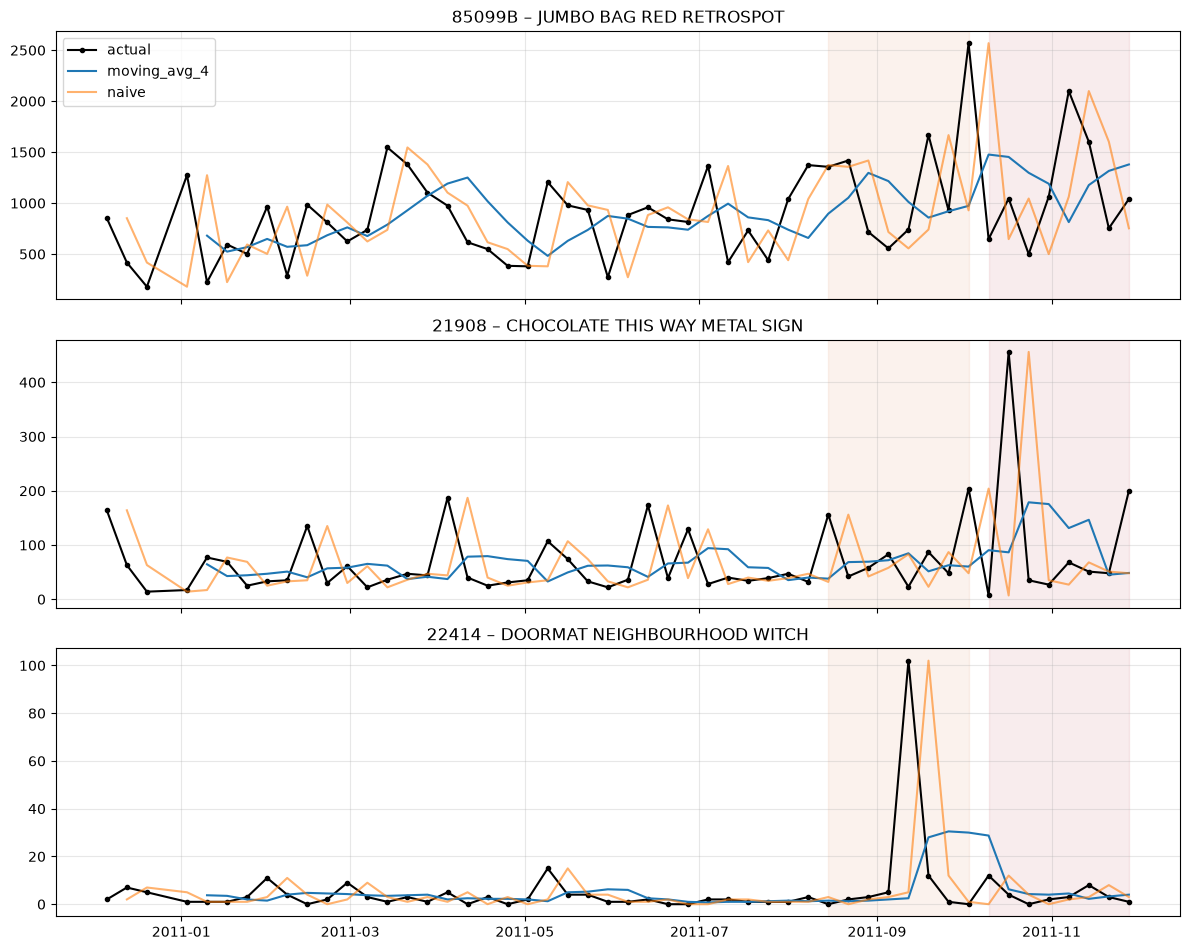

In [15]:
examples = by_prod.sort_values("MAE", ascending=False)["StockCode"].iloc[[0, len(by_prod)//4, len(by_prod)//2]].tolist()
b1 = baselines[baselines["horizon"] == 1]
fig, axes = plt.subplots(len(examples), 1, figsize=(12, 3.2 * len(examples)), sharex=True)
for ax, code_ in zip(axes, examples):
    d = b1[b1["StockCode"] == code_]
    ax.plot(d["week_start"], d["units_sold"], "k-o", markersize=3, label="actual")
    ax.plot(d["week_start"], d["moving_avg_4"], label="moving_avg_4")
    ax.plot(d["week_start"], d["naive"], alpha=0.6, label="naive")
    ax.axvspan(VALID_START, VALID_END, color="#DD8452", alpha=0.1)
    ax.axvspan(TEST_START, TEST_END, color="#C44E52", alpha=0.1)
    name = mp.loc[mp["StockCode"] == code_, "Description"].iat[0]
    ax.set_title(f"{code_} – {name}"); ax.grid(alpha=0.3)
axes[0].legend(loc="upper left")
save_fig("24_example_products")

## 9. Summary

**Scope and setup**
- **Products:** 978 of 3,492 products are forecast at weekly level. They cover 70.4% of train-period units and were selected on train data only.
- **Feature tables:** 49,878 product-weeks per horizon, 28 features each. The weeks of 29 Nov 2010, 27 Dec 2010 and 5 Dec 2011 were removed as closed or partial.
- **Split:** train 35 weeks (6 Dec 2010 – 8 Aug 2011), validation 8 weeks (15 Aug – 3 Oct 2011), test 8 weeks (10 Oct – 28 Nov 2011).
- **Leakage:** checks pass for both horizons at three cutoffs. No feature correlates above 0.63 with the target.

**Baseline results**
- **Best baseline:** `moving_avg_4` is best in every split and horizon. On test, its product-level WAPE is 61.8% (h = 1) and 65.8% (h = 4), against 73.4% and 77.2% for `naive`.
- **Product-level error:** this is high (WAPE about 60–80%) because individual product demand is noisy and often intermittent. Summed to total demand, the same forecasts are much more accurate: `moving_avg_4` total-level WAPE is 16.5% on validation and 10.5% on test (h = 1).
- **Under-forecasting:** bias is negative (about −2% to −9%). The baselines lag behind the autumn ramp-up, which matters for replenishment because it means a risk of stockouts.
- **Seasonal naive:** `seasonal_naive_52` has 0% coverage, because the data has no previous year. The 4-week seasonal proxy is worse than `naive`, so there is no useful monthly cycle.

**Targets for Week 3**
- Models must beat `moving_avg_4` on **validation WAPE** (h = 1: 67.95%, h = 4: 69.42%) and reduce the negative bias.
- The test period is used once, only for the final comparison.
- Train on `features_h1.csv` / `features_h4.csv` with `split == "train"` and tune on `split == "validation"`.
- Rows with `has_full_history == False` have missing lags. XGBoost handles these as-is; Random Forest needs them dropped or filled.

**Limitations**
- **One year of data:** yearly seasonality cannot be learned, and validation and test sit in a peak season the train period never saw.
- **No stockout, inventory or promotion fields:** zeros may hide stockouts, and promotion effects are only approximated by past price changes.
- **No store dimension:** forecasts are at product level only.